# Entrenamiento 

In [1]:
import os
os.chdir("/home/jovyan/work/repo_conteo_gallinas")
os.environ["CUDA_VISIBLE_DEVICES"] = "0, 2"

import torch
from ultralytics import YOLO



In [3]:
import torch

print("CUDA disponible:", torch.cuda.is_available())
print("Número de GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(i, torch.cuda.get_device_name(i))



CUDA disponible: True
Número de GPUs: 2
0 NVIDIA RTX 6000 Ada Generation
1 NVIDIA RTX 6000 Ada Generation


In [9]:
# Eliminar carpeta de resultados previos
import shutil
if os.path.exists("runs"):
    shutil.rmtree("runs")



In [11]:
MODEL_EPOCHS = 50
MODEL_BATCH = 8
MODEL_LR = 0.01
MODEL_OPTIMIZER = 'SGD'

model = YOLO("model/yolo26m.pt")


In [12]:
model.train(
    data="/home/jovyan/work/repo_conteo_gallinas/artifacts/full_dataset.yaml",
    imgsz=640,
    epochs=MODEL_EPOCHS,
    batch=MODEL_BATCH,
    lr0=MODEL_LR,
    optimizer=MODEL_OPTIMIZER,
    # device=0,
    device=[0, 1],
    workers=0,
    project='.',
    name='.'
)



Ultralytics 8.4.96 🚀 Python-3.13.11 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX 6000 Ada Generation, 48640MiB)
                                                       CUDA:1 (NVIDIA RTX 6000 Ada Generation, 48632MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/jovyan/work/repo_conteo_gallinas/artifacts/full_dataset.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0,

{'metrics/precision(B)': 0.60995,
 'metrics/recall(B)': 0.58356,
 'metrics/mAP50(B)': 0.55608,
 'metrics/mAP50-95(B)': 0.18235,
 'val/box_loss': 2.46129,
 'val/cls_loss': 1.35852,
 'val/dfl_loss': 0.00999,
 'fitness': 0.18235}

In [13]:
# Ver métricas
import pandas as pd

df = pd.read_csv("runs/detect/results.csv")
df

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,16.8989,3.07070,3.45444,0.00966,0.06513,0.16979,0.01818,0.00433,2.66008,2.95884,0.01104,0.000600,0.000600,0.094600
1,2,18.4705,2.89569,3.38127,0.00944,0.08462,0.22059,0.03085,0.00734,2.61890,2.81543,0.01079,0.001274,0.001274,0.088274
2,3,19.7510,3.04111,3.17168,0.00867,0.12333,0.32152,0.07572,0.01979,2.57697,2.51103,0.01062,0.001921,0.001921,0.081921
3,4,21.1325,2.90560,2.74886,0.00808,0.19496,0.25221,0.09413,0.02630,2.57338,3.14355,0.01053,0.002540,0.002540,0.075540
4,5,22.5542,2.65659,2.61289,0.00823,0.20359,0.26805,0.10836,0.02977,2.57491,3.93095,0.01048,0.003131,0.003131,0.069131
5,6,24.3530,2.65288,2.36686,0.00734,0.19533,0.34759,0.12772,0.03427,2.51032,2.52957,0.01018,0.003694,0.003694,0.062694
6,7,25.5676,2.45787,2.17654,0.00671,0.21850,0.34759,0.14321,0.03875,2.50161,2.62494,0.01016,0.004230,0.004230,0.056230
7,8,26.7467,2.53737,2.04537,0.00651,0.25274,0.42781,0.19386,0.05332,2.48575,2.49442,0.01012,0.004738,0.004738,0.049738
8,9,28.0835,2.60521,2.04338,0.00682,0.27512,0.44044,0.21697,0.05998,2.50489,2.13359,0.01023,0.005218,0.005218,0.043218
9,10,29.2626,2.47738,1.97075,0.00632,0.31525,0.42981,0.24390,0.06881,2.51718,2.10853,0.01028,0.005670,0.005670,0.036670


In [20]:
epoca_final = int(df["epoch"].max())
tiempo_final = float(df["time"].max())
map50_final = float(df["metrics/mAP50(B)"].max())
map5095_final = float(df["metrics/mAP50-95(B)"].max())


0.55608

In [26]:
best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
best


epoch                   45.000000
time                    71.060500
train/box_loss           2.241390
train/cls_loss           1.365390
train/dfl_loss           0.006890
metrics/precision(B)     0.609950
metrics/recall(B)        0.583560
metrics/mAP50(B)         0.556080
metrics/mAP50-95(B)      0.182350
val/box_loss             2.461290
val/cls_loss             1.358520
val/dfl_loss             0.009990
lr/pg0                   0.001288
lr/pg1                   0.001288
lr/pg2                   0.001288
Name: 44, dtype: float64

In [31]:
float(best["metrics/mAP50(B)"])



0.55608

In [22]:
# best["metrics/mAP50(B)"], best["metrics/mAP50-95(B)"]


## Aplicación


In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def resize_with_aspect_and_padding(image, target_size):
    h, w = image.shape[:2]
    scale = min(target_size[1] / h, target_size[0] / w)  # Calcula el factor de escala
    new_w = int(w * scale)
    new_h = int(h * scale)
    resized_image = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    # Crear un lienzo blanco del tamaño target_size
    padded_image = np.full((target_size[1], target_size[0], 3), 255, dtype=np.uint8)

    # Calcular el desplazamiento para centrar la imagen
    y_offset = (target_size[1] - new_h) // 2
    x_offset = (target_size[0] - new_w) // 2

    # Insertar la imagen redimensionada en el lienzo
    padded_image[y_offset:y_offset + new_h, x_offset:x_offset + new_w] = resized_image

    return padded_image, (scale, x_offset, y_offset)


In [30]:
ruta_local = "data/processed/20260728_083048_tp00013/20260728_083048_tp00013_t0040s_3.jpg"
im_name = os.path.splitext(os.path.basename(ruta_local))[0]

image = cv2.imread(ruta_local)

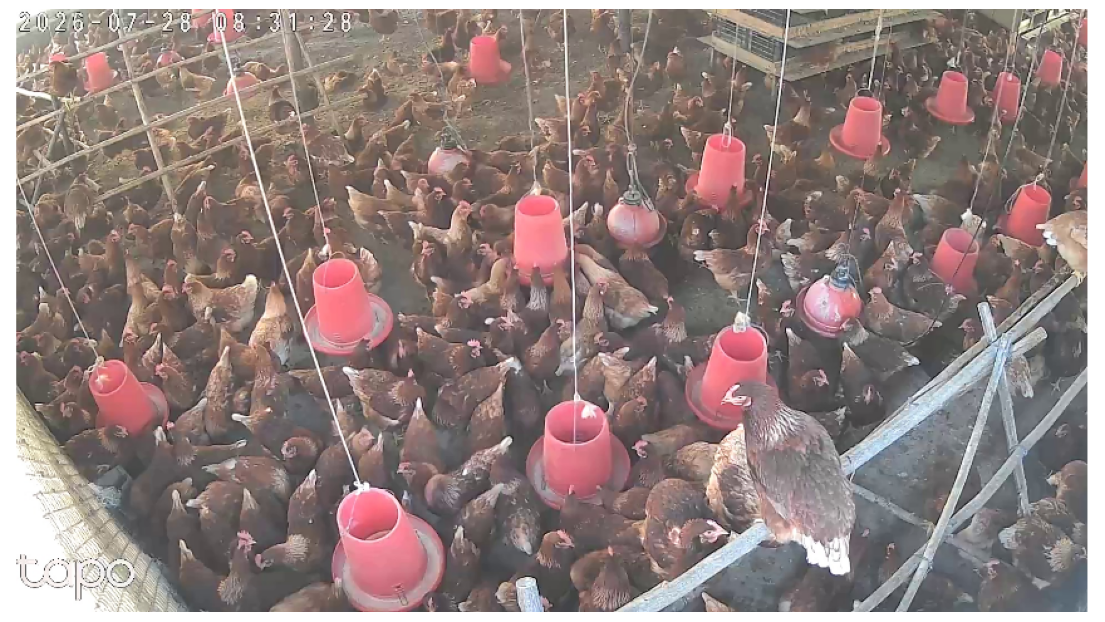

In [31]:
processed_image, (scale, x_offset, y_offset) = resize_with_aspect_and_padding(image, (864, 480))
result_image_rgb = cv2.cvtColor(processed_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 10))
plt.imshow(result_image_rgb)
plt.axis("off")
plt.show()

In [37]:
from ultralytics import YOLO

model = YOLO("runs/detect/model_results/weights/best.pt")
results = model(ruta_local)
# results = model(ruta_local, conf=0.25)



image 1/1 /home/jovyan/work/repo_conteo_gallinas/data/processed/20260728_083048_tp00013/20260728_083048_tp00013_t0040s_3.jpg: 384x640 76 gallinas, 5.1ms
Speed: 1.3ms preprocess, 5.1ms inference, 0.2ms postprocess per image at shape (1, 3, 384, 640)


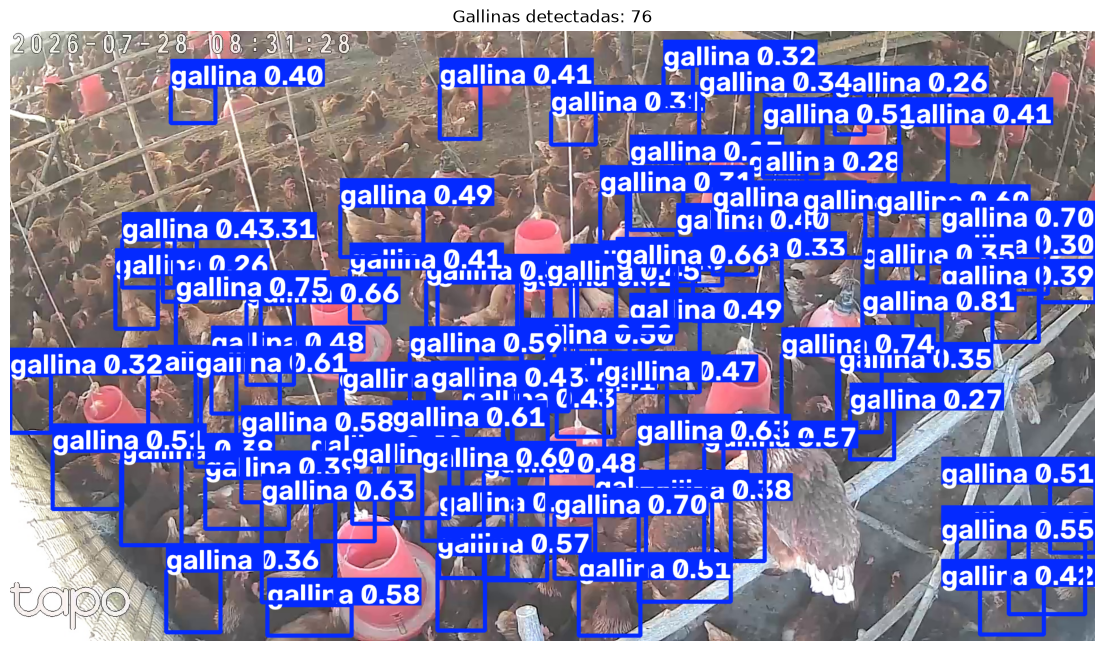

In [40]:
annotated = results[0].plot()
# annotated = results[0].plot(
#     line_width=1,   # grosor de la caja
#     font_size=0.4  # tamaño del texto
# )

plt.figure(figsize=(14,10))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Gallinas detectadas: {len(results[0].boxes)}")
plt.show()


image 1/1 /home/jovyan/work/repo_conteo_gallinas/data/processed/20260728_083048_tp00013/20260728_083048_tp00013_t0720s_37.jpg: 384x640 70 gallinas, 5.3ms
Speed: 16.7ms preprocess, 5.3ms inference, 0.3ms postprocess per image at shape (1, 3, 384, 640)


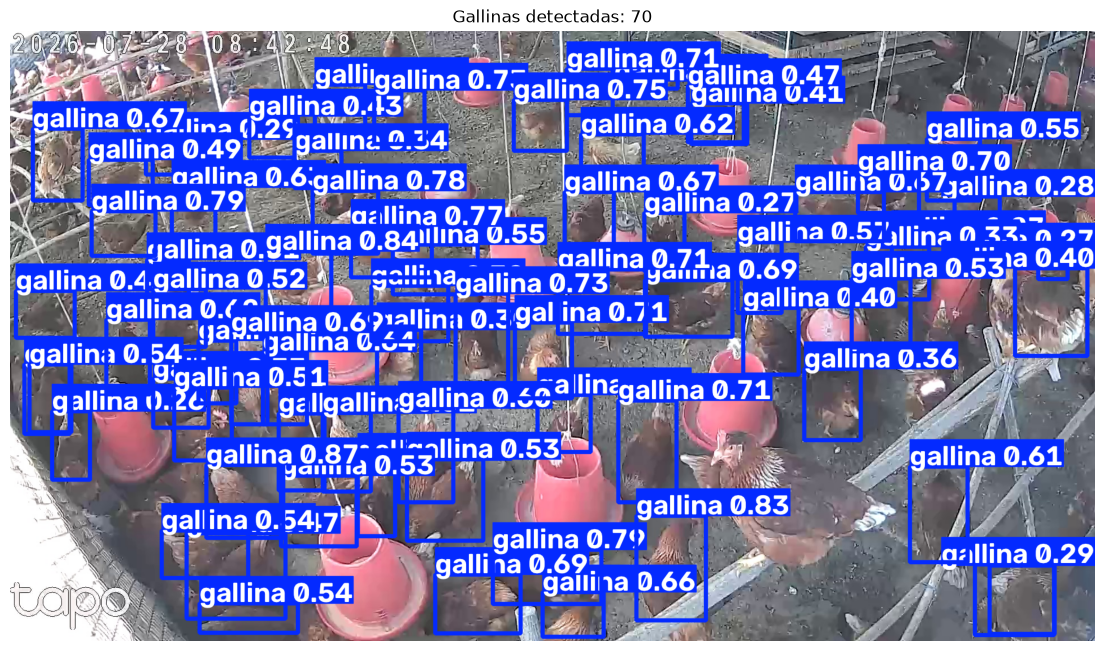

In [42]:

ruta_local = "data/processed/20260728_083048_tp00013/20260728_083048_tp00013_t0720s_37.jpg"
results = model(ruta_local)
annotated = results[0].plot()

plt.figure(figsize=(14,10))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Gallinas detectadas: {len(results[0].boxes)}")
plt.show()
